<a href="https://colab.research.google.com/github/Fata-Haidar/244107020108-Pembelajaran-Mesin/blob/main/JS07/Tugas_js07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Import library, membaca dan menyiapkan dataset**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score
)
from sklearn.neighbors import NearestNeighbors

# Membaca dataset
df = pd.read_csv('CC_Customer_Dataset.csv')

# Melihat data
print(df.head())
print(df.info())

   Sl_No  Customer Key  Avg_Credit_Limit  Total_Credit_Cards  \
0      1         87073            100000                   2   
1      2         38414             50000                   3   
2      3         17341             50000                   7   
3      4         40496             30000                   5   
4      5         47437            100000                   6   

   Total_visits_bank  Total_visits_online  Total_calls_made  
0                  1                    1                 0  
1                  0                   10                 9  
2                  1                    3                 4  
3                  1                    1                 4  
4                  0                   12                 3  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    i

**1. Scatterplot Avg_Credit_Limit dan Total_Credit_Cards**

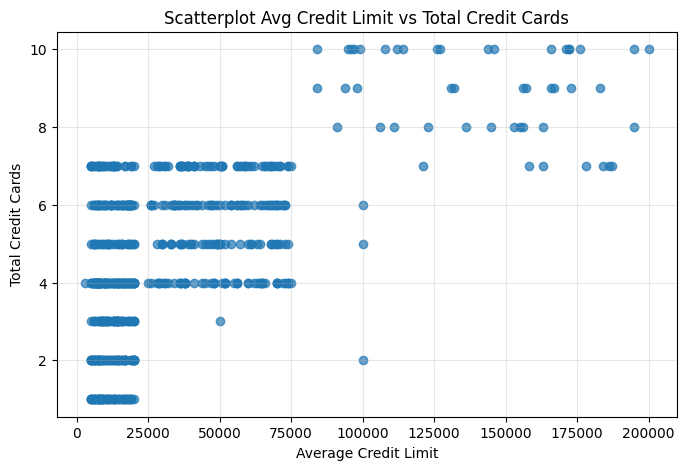

Korelasi Pearson: 0.609


In [2]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df['Avg_Credit_Limit'],
    df['Total_Credit_Cards'],
    alpha=0.7
)

plt.xlabel('Average Credit Limit')
plt.ylabel('Total Credit Cards')
plt.title('Scatterplot Avg Credit Limit vs Total Credit Cards')
plt.grid(True, alpha=0.3)
plt.show()

# Menghitung korelasi
corr = df['Avg_Credit_Limit'].corr(
    df['Total_Credit_Cards']
)

print(f'Korelasi Pearson: {corr:.3f}')

Scatterplot digunakan untuk melihat hubungan antara Avg_Credit_Limit dan Total_Credit_Cards. Berdasarkan nilai korelasi Pearson sekitar 0,609, kedua variabel memiliki hubungan positif dengan kekuatan sedang hingga cukup kuat. Artinya, pelanggan dengan jumlah kartu kredit lebih banyak cenderung memiliki rata-rata limit kredit yang lebih tinggi. Namun, sebaran data tidak harus sepenuhnya linier karena dapat terdapat kelompok pelanggan dengan karakteristik yang berbeda.

**2. Model K-Means dan menentukan nilai k dengan elbow method**

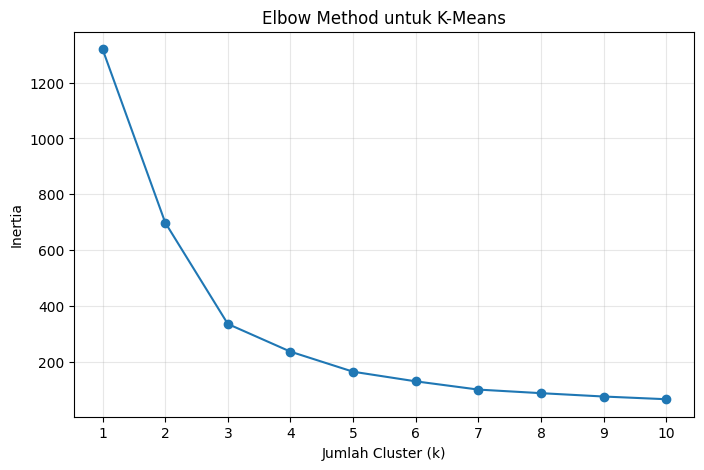

In [3]:
# Memilih dua fitur
features = [
    'Avg_Credit_Limit',
    'Total_Credit_Cards'
]

X = df[features]

# Standardisasi
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Elbow method
inertia = []

K = range(1, 11)

for k in K:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Linechart elbow method
plt.figure(figsize=(8, 5))
plt.plot(K, inertia, marker='o')

plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method untuk K-Means')
plt.xticks(list(K))
plt.grid(True, alpha=0.3)
plt.show()

Elbow method digunakan untuk menentukan jumlah cluster yang sesuai dengan mengamati perubahan nilai inertia. Semakin banyak cluster, nilai inertia cenderung semakin kecil. Nilai k = 3 dapat dipilih apabila grafik menunjukkan bahwa penurunan inertia mulai melambat setelah tiga cluster. Dengan demikian, tiga cluster dianggap sebagai kompromi antara kekompakan kelompok dan kompleksitas model.

**3. Visualisasi hasil klasterisasi K-Means**

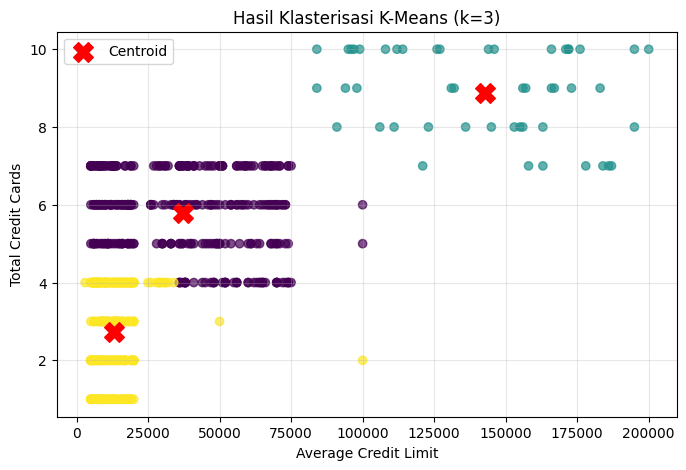

KMeans_Cluster
0    330
1     48
2    282
Name: count, dtype: int64


In [4]:
# Membuat model K-Means
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

# Scatterplot berdasarkan cluster
plt.figure(figsize=(8, 5))

plt.scatter(
    df['Avg_Credit_Limit'],
    df['Total_Credit_Cards'],
    c=df['KMeans_Cluster'],
    cmap='viridis',
    alpha=0.7
)

# Titik pusat cluster dikembalikan ke skala asli
centers = scaler.inverse_transform(kmeans.cluster_centers_)

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker='X',
    s=200,
    c='red',
    label='Centroid'
)

plt.xlabel('Average Credit Limit')
plt.ylabel('Total Credit Cards')
plt.title('Hasil Klasterisasi K-Means (k=3)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Jumlah anggota setiap cluster
print(df['KMeans_Cluster'].value_counts().sort_index())

Scatterplot menunjukkan pembagian pelanggan menjadi tiga cluster berdasarkan rata-rata limit kredit dan jumlah kartu kredit. Setiap warna mewakili kelompok pelanggan yang berbeda, sedangkan tanda silang menunjukkan pusat masing-masing cluster. Perbedaan karakteristik tiap kelompok dapat dijelaskan menggunakan nilai rata-rata kedua variabel pada setiap cluster.

In [5]:
print(
    df.groupby('KMeans_Cluster')[features]
      .mean()
      .round(2)
)

                Avg_Credit_Limit  Total_Credit_Cards
KMeans_Cluster                                      
0                       37160.61                5.79
1                      142750.00                8.88
2                       13134.75                2.73


**4. Model DBSCAN menggunakan seluruh variabel yang dapat digunakan**

In [6]:
# Memilih semua variabel fitur yang relevan
features_all = [
    'Avg_Credit_Limit',
    'Total_Credit_Cards',
    'Total_visits_bank',
    'Total_visits_online',
    'Total_calls_made'
]

X_all = df[features_all]

# Standardisasi semua fitur
scaler_db = StandardScaler()
X_all_scaled = scaler_db.fit_transform(X_all)

# Membuat model DBSCAN
dbscan = DBSCAN(
    eps=1.3,
    min_samples=5
)

df['DBSCAN_Cluster'] = dbscan.fit_predict(X_all_scaled)

# Melihat jumlah anggota setiap cluster
print(df['DBSCAN_Cluster'].value_counts().sort_index())

DBSCAN_Cluster
-1      2
 0    608
 1     50
Name: count, dtype: int64


DBSCAN mengelompokkan pelanggan berdasarkan kepadatan data dengan menggunakan lima variabel karakteristik pelanggan yang telah distandardisasi. Model ini tidak memerlukan penentuan jumlah cluster di awal dan dapat mengidentifikasi pelanggan yang tidak termasuk kelompok padat sebagai noise. Label -1 pada hasil model menunjukkan data noise.

**5. Menentukan parameter DBSCAN menggunakan k-distance plot**

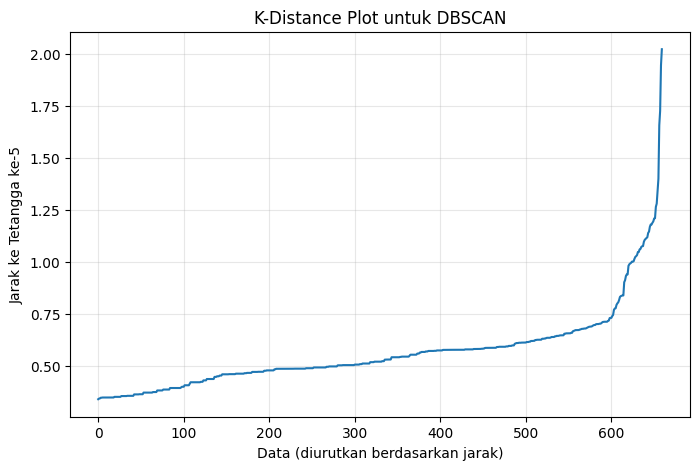

In [7]:
# Menghitung jarak ke tetangga ke-5
neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X_all_scaled)

distances, indices = neighbors_fit.kneighbors(X_all_scaled)

# Mengurutkan jarak dari terkecil ke terbesar
distances = np.sort(distances[:, -1])

# Membuat linechart
plt.figure(figsize=(8, 5))
plt.plot(distances)

plt.xlabel('Data (diurutkan berdasarkan jarak)')
plt.ylabel('Jarak ke Tetangga ke-5')
plt.title('K-Distance Plot untuk DBSCAN')
plt.grid(True, alpha=0.3)
plt.show()

Untuk DBSCAN, metode yang lebih sesuai adalah k-distance plot, bukan elbow method K-Means, karena DBSCAN menggunakan parameter eps dan min_samples, bukan jumlah cluster k. Nilai eps diperkirakan dari titik ketika grafik jarak ke tetangga terdekat mulai meningkat tajam. Parameter yang dipilih kemudian diuji untuk melihat jumlah cluster dan noise yang terbentuk.

In [8]:
for eps in [1.0, 1.2, 1.3, 1.4, 1.5]:
    model = DBSCAN(eps=eps, min_samples=5)
    labels = model.fit_predict(X_all_scaled)

    n_clusters = len(set(labels) - {-1})
    n_noise = np.sum(labels == -1)

    print(
        f'eps={eps:.1f} | '
        f'Jumlah cluster={n_clusters} | '
        f'Jumlah noise={n_noise}'
    )

eps=1.0 | Jumlah cluster=2 | Jumlah noise=18
eps=1.2 | Jumlah cluster=2 | Jumlah noise=4
eps=1.3 | Jumlah cluster=2 | Jumlah noise=2
eps=1.4 | Jumlah cluster=2 | Jumlah noise=1
eps=1.5 | Jumlah cluster=2 | Jumlah noise=1


6. Menghitung Silhouette Score dan Davies-Bouldin Index (DBI) DBSCAN

In [9]:
# Mengambil label cluster DBSCAN
labels = df['DBSCAN_Cluster'].values

# Mengabaikan titik noise untuk evaluasi cluster
mask = labels != -1

X_eval = X_all_scaled[mask]
labels_eval = labels[mask]

# Memastikan ada minimal dua cluster
n_clusters = len(set(labels_eval))

if n_clusters >= 2:
    silhouette = silhouette_score(X_eval, labels_eval)
    dbi = davies_bouldin_score(X_eval, labels_eval)

    print(f'Silhouette Score: {silhouette:.4f}')
    print(f'Davies-Bouldin Index: {dbi:.4f}')
else:
    print('Metrik tidak dapat dihitung karena kurang dari dua cluster.')

Silhouette Score: 0.5721
Davies-Bouldin Index: 0.6349


Silhouette Score digunakan untuk menilai seberapa baik data berada dalam clusternya dibandingkan dengan cluster lain. Nilai yang semakin mendekati 1 umumnya menunjukkan pemisahan cluster yang semakin baik. Sementara itu, Davies-Bouldin Index (DBI) mengukur kekompakan dan pemisahan antarkelompok, dengan nilai lebih rendah umumnya menunjukkan kualitas cluster yang lebih baik. Pada DBSCAN, perhitungan sebaiknya menyebutkan apakah data noise dikeluarkan dari evaluasi.